Cleaning and exploring the data from my baseline imports

In [1]:
import os
import sys
sys.path.insert(0, "../src")

from processor import *
from reusables import *

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

In [2]:
DB_PATH = "Desktop/Data Analysis/incident_log.db"
START = '2026-10-12'

Clean and prepare data for analysis below.

In [3]:
df, jobs, issues = prepare("../incident_log.db", start="2026-10-12")
weekly = weekly_summary(df, jobs)
print(len(df), 'incidents loaded')

22 incidents loaded


In [4]:
issues

,severity,check,incident_id,detail
0,ERROR,missing_required,16.0,Lost Item: 'item' is empty
1,ERROR,missing_required,15.0,Lost Item: 'item' is empty
2,ERROR,missing_required,14.0,Lost Item: 'item' is empty
3,ERROR,missing_required,13.0,Lost Item: 'item' is empty
4,ERROR,missing_required,12.0,Lost Item: 'item' is empty
5,ERROR,missing_required,16.0,Lost Item: 'last_location' is empty
6,ERROR,missing_required,15.0,Lost Item: 'last_location' is empty
7,ERROR,missing_required,14.0,Lost Item: 'last_location' is empty
8,ERROR,missing_required,13.0,Lost Item: 'last_location' is empty
9,ERROR,missing_required,12.0,Lost Item: 'last_location' is empty


Exploration of the baseline data. Asking questions and trying to find answers about the data.

Setting variables for the baseline week and the last week.

In [ ]:
baseline  = df[df['id'].between(3, 16)]
last_week = df.drop(baseline.index)

What is the broken-down cost by waste type for the baseline input week?

In [5]:
cost_by(baseline)

,events,total
kind,,
Lost Item,5,928.8
Breakage,9,745.0


What are the descriptive calculations for the baseline week loss events?

In [6]:
baseline_description = baseline['total_cost'].describe()
baseline_description

count     14.000000
mean     119.557143
std      110.403538
min       21.600000
25%       31.250000
50%       78.600000
75%      161.500000
max      388.800000
Name: total_cost, dtype: float64

How do I visually represent group by kind, especially with the event numbers and totals for the baseline input week?

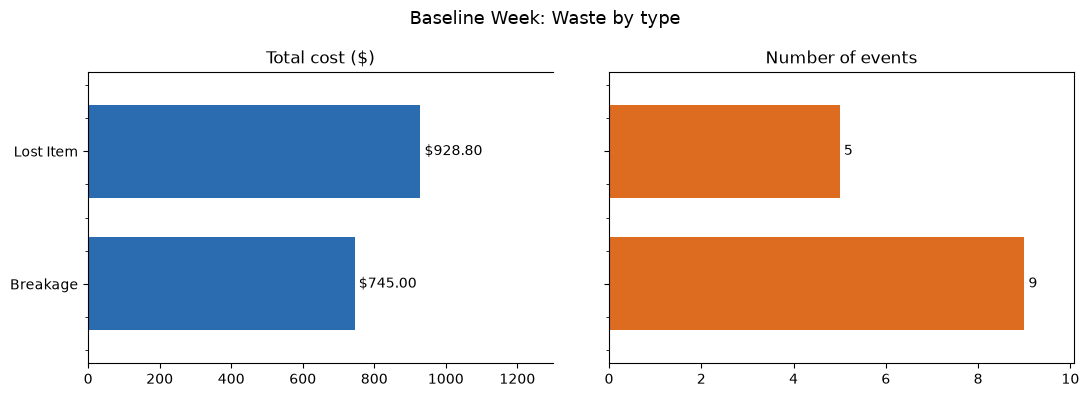

In [14]:
cost_events_chart(cost_by(baseline), 'Baseline Week: Waste by type')

What is the rate for these loss events per 100 jobs?

In [16]:
per_100_jobs(baseline, 36)

,events,total,events_per_100,cost_per_100
kind,,,,
Lost Item,5,928.8,13.9,2580.00
Breakage,9,745.0,25.0,2069.44


Conclusion (baseline week):
    - Lost items account for most of the financial losses while also being fewer in event quantity than breakage.
    - Per 100 jobs calc was done based off of 36 jobs in that week.
        - If losses continue at the same per 100 jobs rate as baseline then:
            - Over a year (another 51 weeks), breakage per 100 jobs will cost ~$35,870.
                ~ 433 events per year.
            - Over a year (another 51 weeks), lost items per 100 jobs will cost ~$43,860.
                ~ 243 events per year.
        - In total if this projection continues for a year, it will cost ~$79,730 and there will be 
           ~676 events over that time.
    - These numbers must be compared against the numbers from the first reporting week (10/12 - 10/16)